# 04 · Machine learning — Current EV use

**Binary target:** `ev_use` — whether a responding firm operates small-cargo electric vehicles. This notebook deliberately does not merge existing EV use with EV consideration. Both predictor scenarios are run with preprocessing *inside* every validation fold. The aim is exploratory model comparison, not deployment-ready risk scoring.

## Survey and outcome-specific sample

In [11]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src'/'ev_research').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
from IPython.display import display, Image
from src.ev_research.data import load_survey, sample_audit, cleaning_audit
from src.ev_research.config import FIGURES, TABLES, FEATURE_SETS, SOURCE_INDEX
from src.ev_research.plotting_style import apply_style
from src.ev_research.statistics import prevalence_table, assumptions_audit, fisher_associations, sensitivity_table
from src.ev_research.figures import *
apply_style()
raw, unique, eligible = load_survey()
print(f'Raw: {len(raw)} | Distinct: {len(unique)} | Eligible: {len(eligible)}')
def show_figure(path, width=1150):
    """Display the exact saved PNG (also exported as vector SVG)."""
    assert path.exists(), f'Missing figure: {path}'
    display(Image(filename=str(path), width=width))
TARGET = 'ev_use'
frame=eligible.loc[eligible[TARGET].notna()].copy()
display(frame[TARGET].value_counts().rename('Responses').to_frame())
print('Positive class prevalence:',f'{frame[TARGET].mean():.1%}')
print('Candidate predictors:')
for scenario,features in FEATURE_SETS.items():
    print(scenario, features)


Raw: 105 | Distinct: 92 | Eligible: 62


,Responses
ev_use,
0.0,45
1.0,15


Positive class prevalence: 25.0%
Candidate predictors:
fleet_baseline ['firm_size', 'fleet_size', 'vehicle_type']
operational_extended ['firm_size', 'fleet_size', 'vehicle_type', 'daily_distance', 'acquisition_type', 'route_planning', 'sector']


## Mathematical foundations and model families

The logistic model estimates

\[\Pr(Y_i=1\mid \mathbf x_i)=\sigma(\beta_0+\mathbf x_i^\top\boldsymbol\beta),\qquad \sigma(z)=\frac{1}{1+e^{-z}}.\]

Regularized binary log-loss is

\[\mathcal L(\boldsymbol\beta)= -\sum_i w_i\left[y_i\log p_i+(1-y_i)\log(1-p_i)\right]+\lambda\|\boldsymbol\beta\|_q^q,\]

with L1 or L2 penalization. Linear SVM minimizes hinge-loss plus complexity penalty; CART/Random Forest split by impurity; LightGBM fits boosted trees. One-hot encoding and imputation belong to the training-fold pipeline. Variables describing EV advantages, perceived disadvantages and the other EV outcome are excluded from the predictor set to avoid post-outcome proxies.

In [12]:
from src.ev_research.models import ALL_MODELS, estimator_specs, make_pipeline, evaluate
from src.ev_research.model_plots import (plot_model_dashboard, plot_roc_dashboard,
    plot_precision_recall_and_confusion, plot_seed_stability)
print('Models:',ALL_MODELS)
# Explicitly examine the feature pipeline rather than hiding it in an opaque wrapper.
from sklearn.linear_model import LogisticRegression
baseline_pipe = make_pipeline(FEATURE_SETS['fleet_baseline'], LogisticRegression(
    class_weight='balanced',solver='liblinear',max_iter=3000,random_state=42))
print(baseline_pipe)


Models: ('dummy', 'logistic_l2', 'logistic_l1', 'linear_svm', 'decision_tree', 'bernoulli_nb', 'random_forest', 'lightgbm')
Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('one_hot',
                                                                   OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                                 min_frequency=2))]),
                                                  ['firm_size', 'fleet_size',
                                                   'vehicle_type'])])),
                ('model',
                 Log

## Nested stratified cross-validation and seeds

**Outer CV:** 3 stratified folds; **inner CV:** 2 folds selecting hyperparameters by balanced accuracy; **split seeds:** 17, 42, 123; **candidate parameter draws:** 2. Out-of-fold predictions are saved per respondent, model, seed, and scenario. Do not treat repeated seeds as independent experimental replicates.

Model-selection and all preprocessing occur **inside training folds**. The saved predictions permit reproducible ROC/PR visualizations without retraining.

In [13]:
# Default is to read saved out-of-fold results from the fully reproducible survey run.
# To retune all models from raw data, set RUN_EVALUATION = True (CPU intensive).
RUN_EVALUATION = True
if RUN_EVALUATION:
    folds,seed_scores,predictions,searches,summary = evaluate(
        eligible,seeds=(17,42,43,123),n_outer=3,n_inner=2,n_iter=2,
        targets=[TARGET], model_names=('dummy','logistic_l2','linear_svm','random_forest','lightgbm'))
    TABLES.mkdir(parents=True,exist_ok=True)
    for name,table in [('folds',folds),('seed_metrics',seed_scores),
                       ('predictions',predictions),('hyperparameters',searches),('summary',summary)]:
        table.to_csv(TABLES/f'{TARGET}_{name}.csv',index=False)
else:
    summary=pd.read_csv(TABLES/f'{TARGET}_summary.csv')
    predictions=pd.read_csv(TABLES/f'{TARGET}_predictions.csv')
    seed_scores=pd.read_csv(TABLES/f'{TARGET}_seed_metrics.csv')
    searches=pd.read_csv(TABLES/f'{TARGET}_hyperparameters.csv')
print('Saved seeds:',sorted(seed_scores.seed.unique()))
display(summary.sort_values(['scenario','balanced_accuracy_mean'],ascending=[True,False]))


Saved seeds: [np.int64(17), np.int64(42), np.int64(43), np.int64(123)]


,outcome,scenario,model,n,seeds,balanced_accuracy_mean,roc_auc_mean,average_precision_mean,f1_mean,recall_mean,specificity_mean,brier_score_mean,balanced_accuracy_sd,roc_auc_sd,average_precision_sd,f1_sd,recall_sd,specificity_sd,brier_score_sd
3,ev_use,fleet_baseline,logistic_l2,60,4,0.672222,0.691481,0.448846,0.508279,0.616667,0.727778,0.218984,0.019245,0.026394,0.047099,0.024408,0.033333,0.063828,0.004862
4,ev_use,fleet_baseline,random_forest,60,4,0.672222,0.715926,0.467987,0.507817,0.666667,0.677778,0.216847,0.081901,0.030872,0.023527,0.092095,0.108866,0.055925,0.007571
2,ev_use,fleet_baseline,linear_svm,60,4,0.647222,0.677037,0.437586,0.474500,0.566667,0.727778,NaN,0.016667,0.036545,0.052780,0.021978,0.086066,0.071146,NaN
1,ev_use,fleet_baseline,lightgbm,60,4,0.644444,0.673519,0.382146,0.477286,0.666667,0.622222,0.234292,0.048855,0.085200,0.058172,0.053867,0.094281,0.087017,0.025569
0,ev_use,fleet_baseline,dummy,60,4,0.500000,0.500000,0.250000,0.000000,0.000000,1.000000,0.187500,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
9,ev_use,operational_extended,random_forest,60,4,0.647222,0.664815,0.508657,0.474981,0.566667,0.727778,0.212015,0.031914,0.035830,0.064028,0.038662,0.066667,0.033333,0.002955
8,ev_use,operational_extended,logistic_l2,60,4,0.641667,0.611481,0.432150,0.472075,0.566667,0.716667,0.229508,0.050816,0.060775,0.089463,0.061404,0.066667,0.096652,0.018577
6,ev_use,operational_extended,lightgbm,60,4,0.625000,0.638704,0.476598,0.446572,0.550000,0.700000,0.232754,0.041944,0.027440,0.057250,0.057894,0.113855,0.066667,0.012449
7,ev_use,operational_extended,linear_svm,60,4,0.583333,0.542963,0.320940,0.394380,0.466667,0.700000,NaN,0.068192,0.039945,0.045041,0.085790,0.121716,0.112583,NaN
5,ev_use,operational_extended,dummy,60,4,0.500000,0.500000,0.250000,0.000000,0.000000,1.000000,0.187500,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


## Accuracy, balanced accuracy, ROC-AUC, and F1

\[\operatorname{BalancedAccuracy}=\tfrac12\left(\frac{TP}{TP+FN}+\frac{TN}{TN+FP}\right),\qquad
F_1=2\frac{\mathrm{precision}\cdot\mathrm{recall}}{\mathrm{precision}+\mathrm{recall}}.\]

Balanced accuracy is the primary ranking metric. ROC-AUC quantifies ranking quality across thresholds, not calibration. Standard deviations show split-seed variability, **not 95% confidence intervals**.

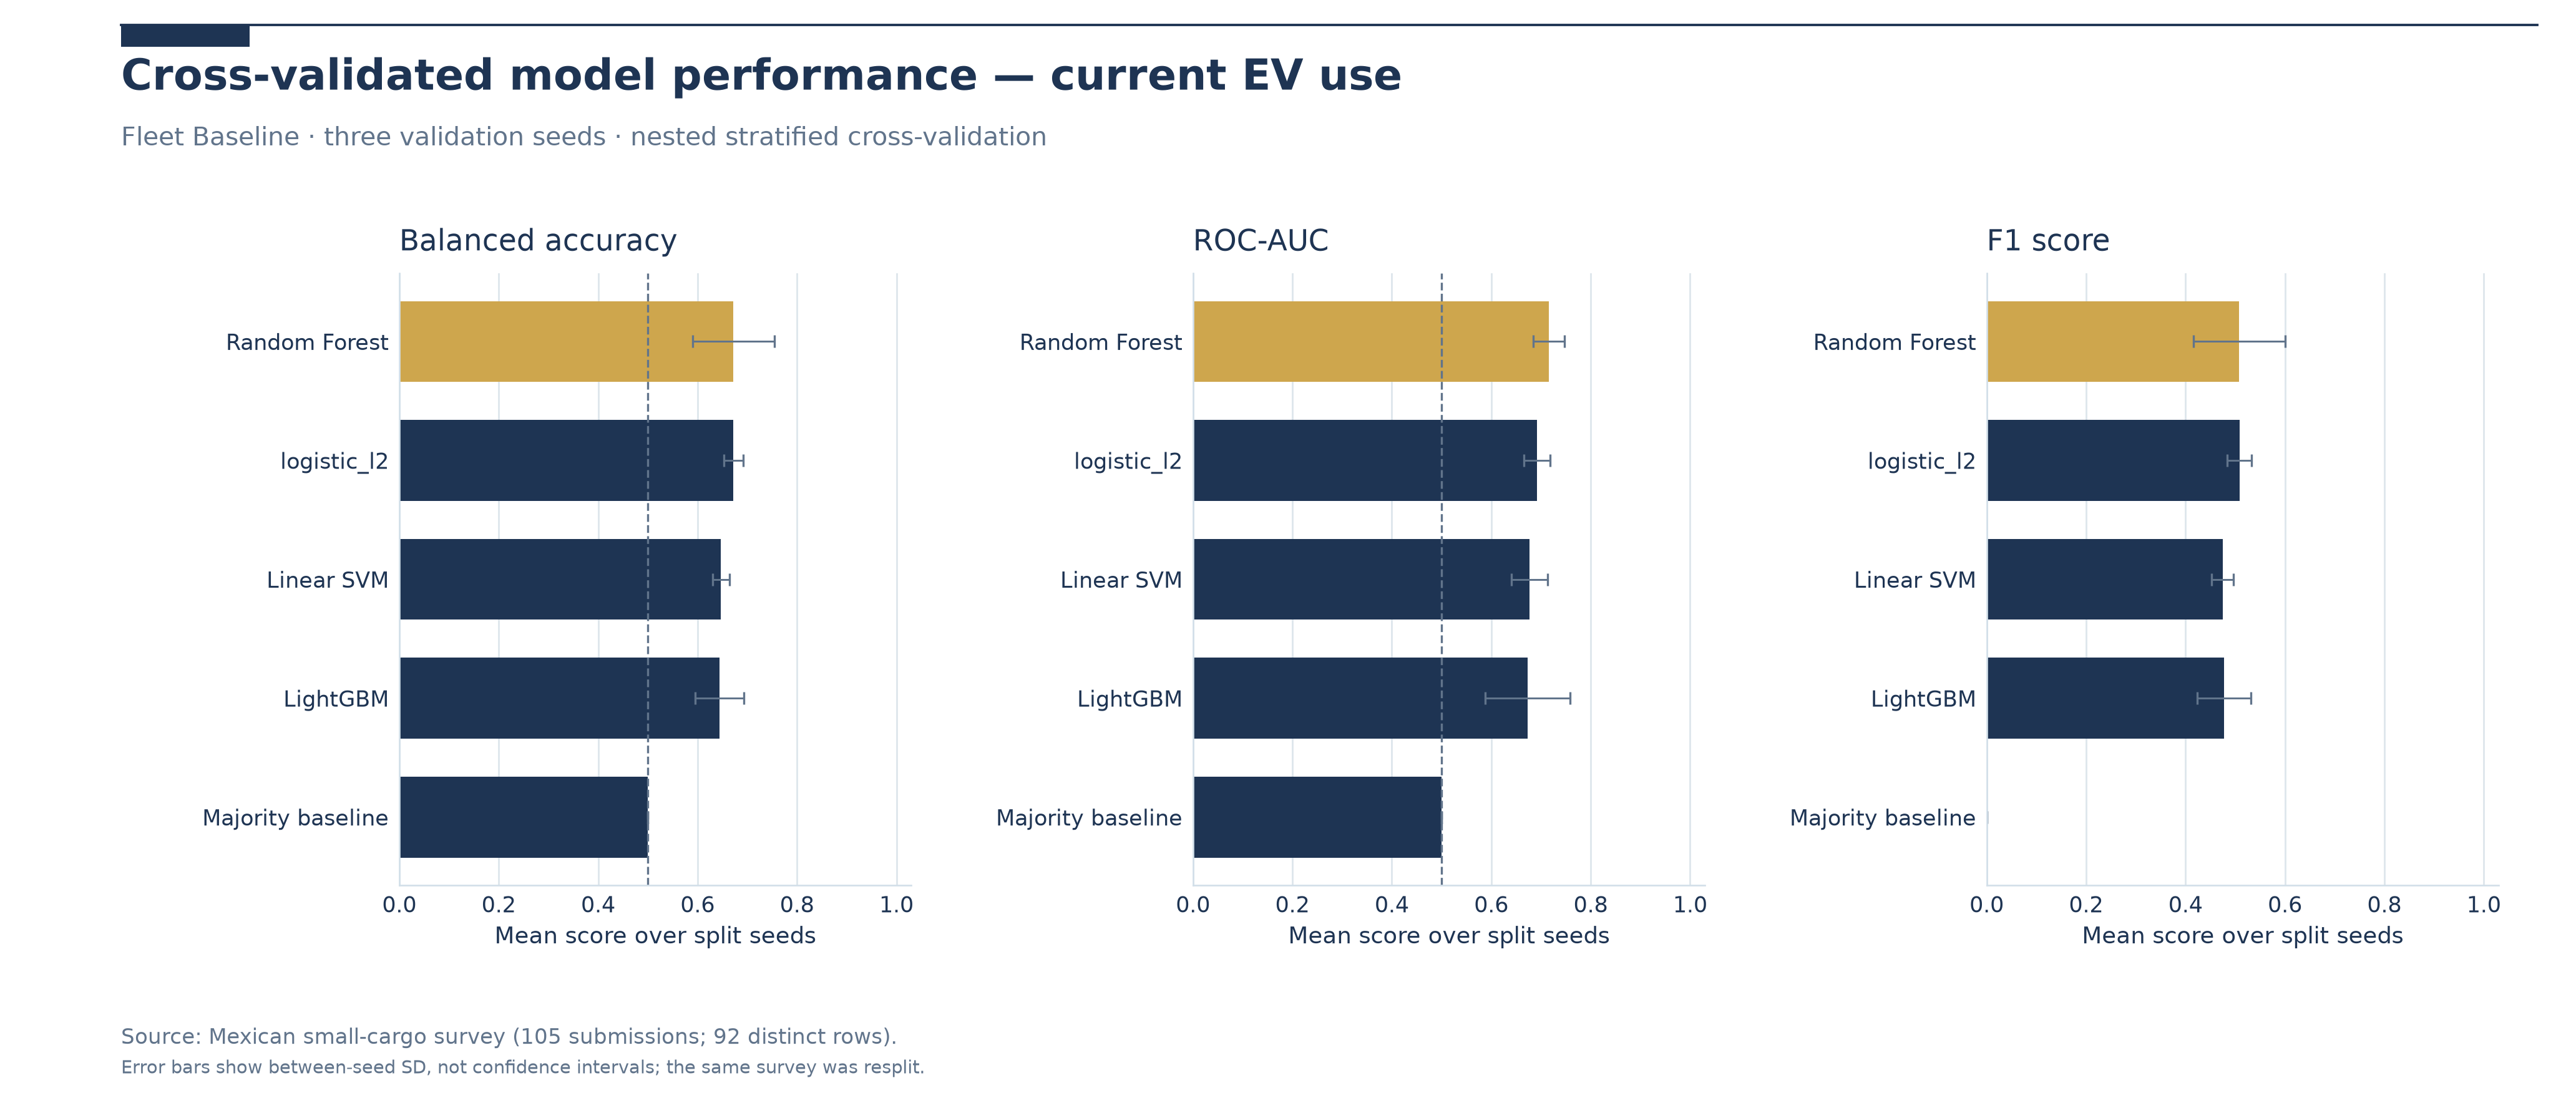

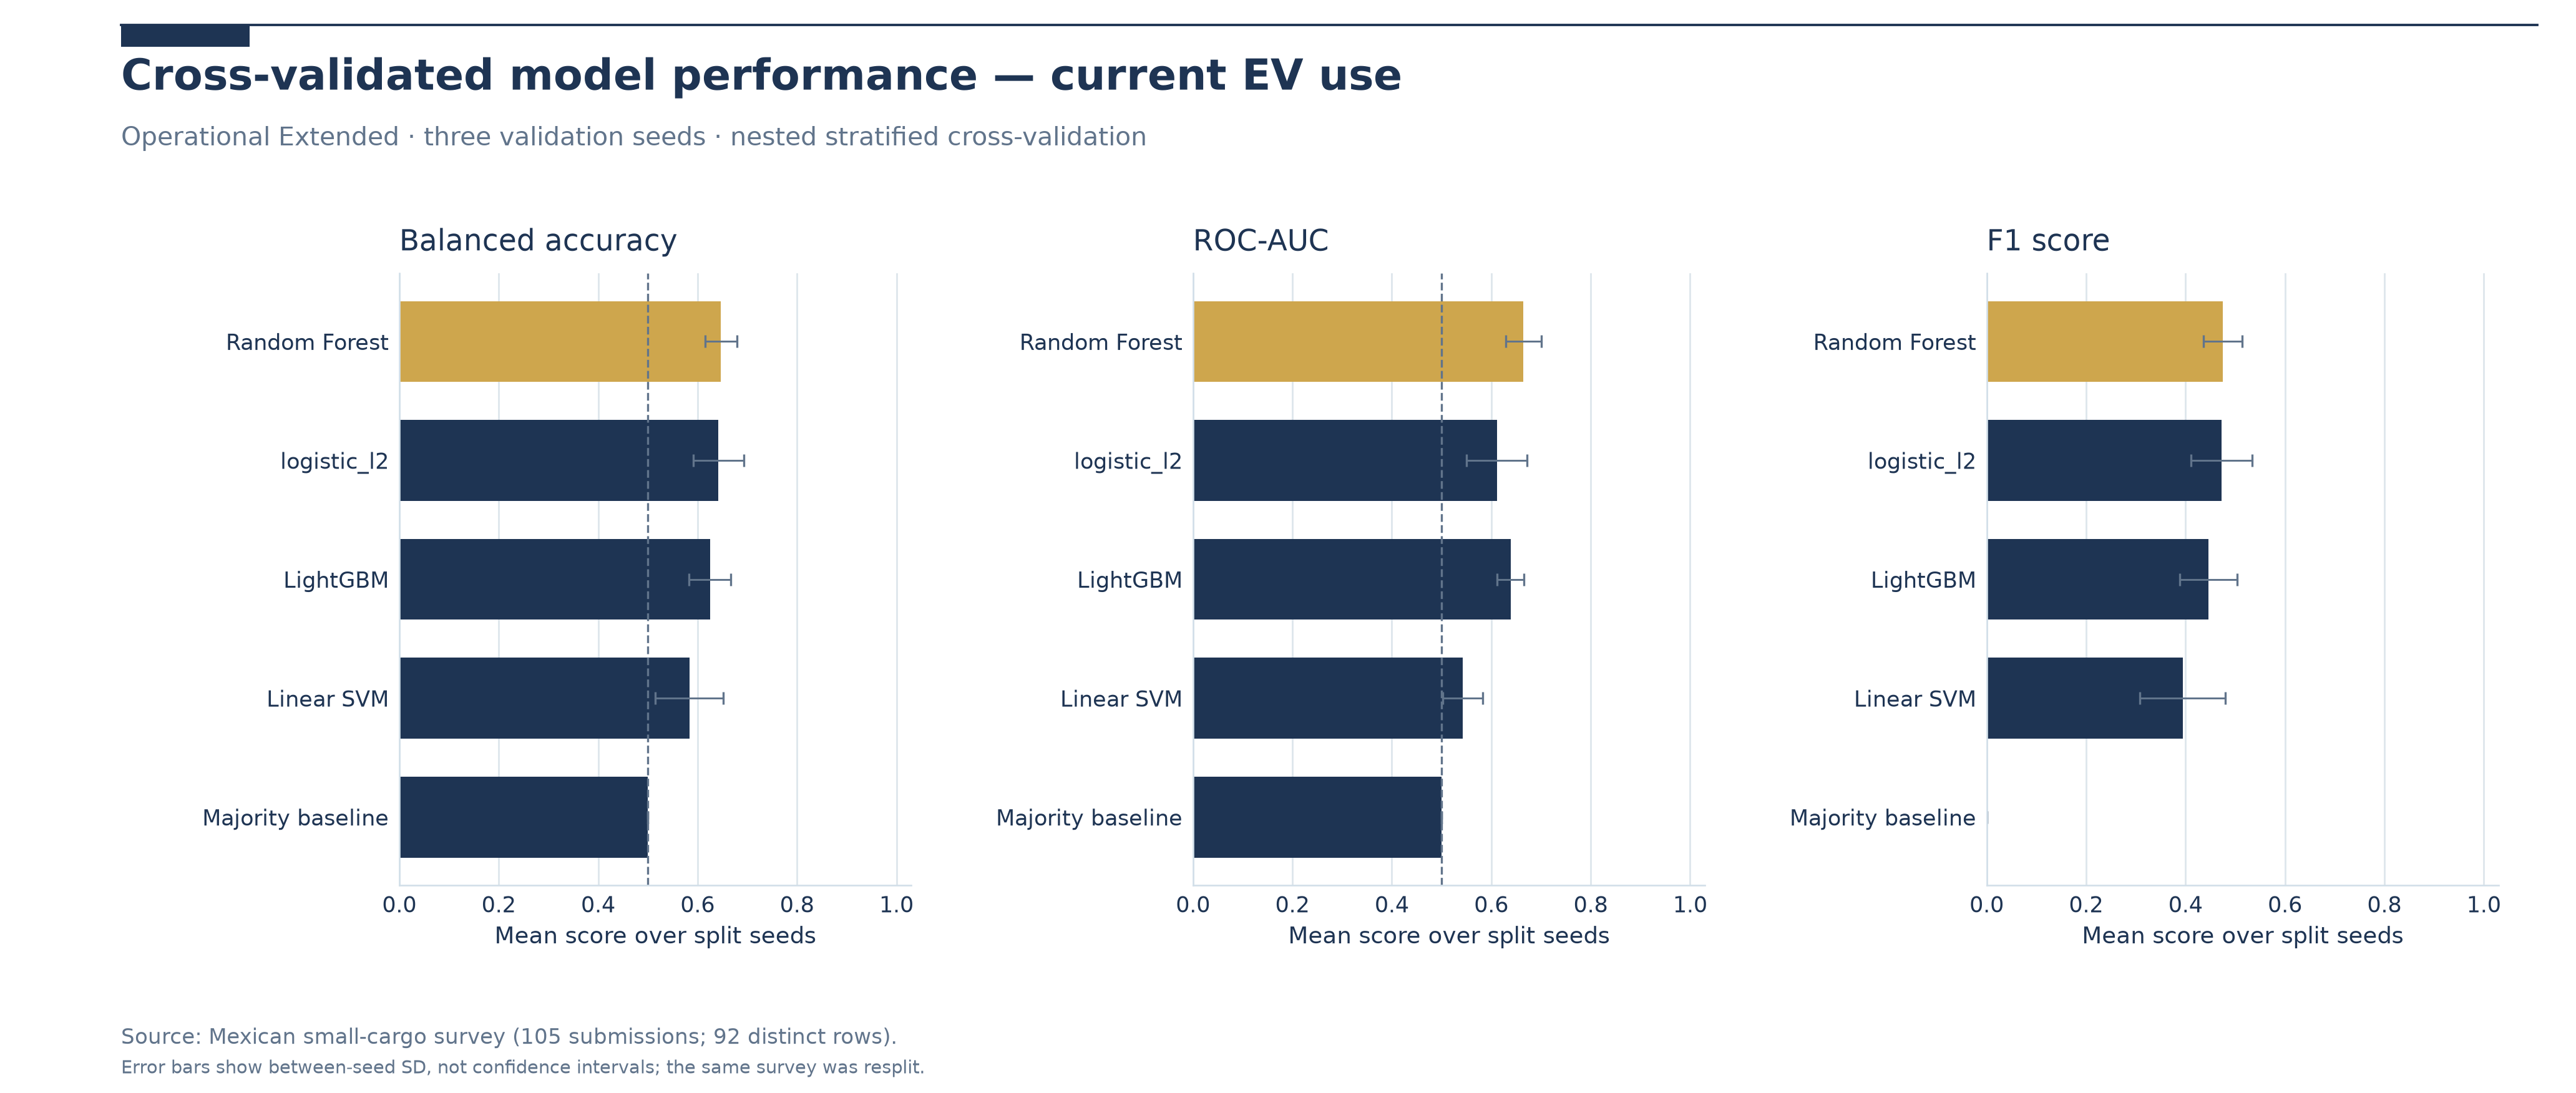

In [14]:
for scenario in FEATURE_SETS:
    plot_model_dashboard(summary,TARGET,scenario)
    show_figure(FIGURES/('03_ev_use' if TARGET=='ev_use' else '04_ev_consideration')/f'02_model_dashboard_{scenario}.png')


## Held-out ROC curves

The left panel compares ROC trajectories; the right compares their scalar AUC values for the same predeclared seed (42). Each model contributes exactly one out-of-fold score per respondent. SVM curves use margins, not calibrated probabilities.

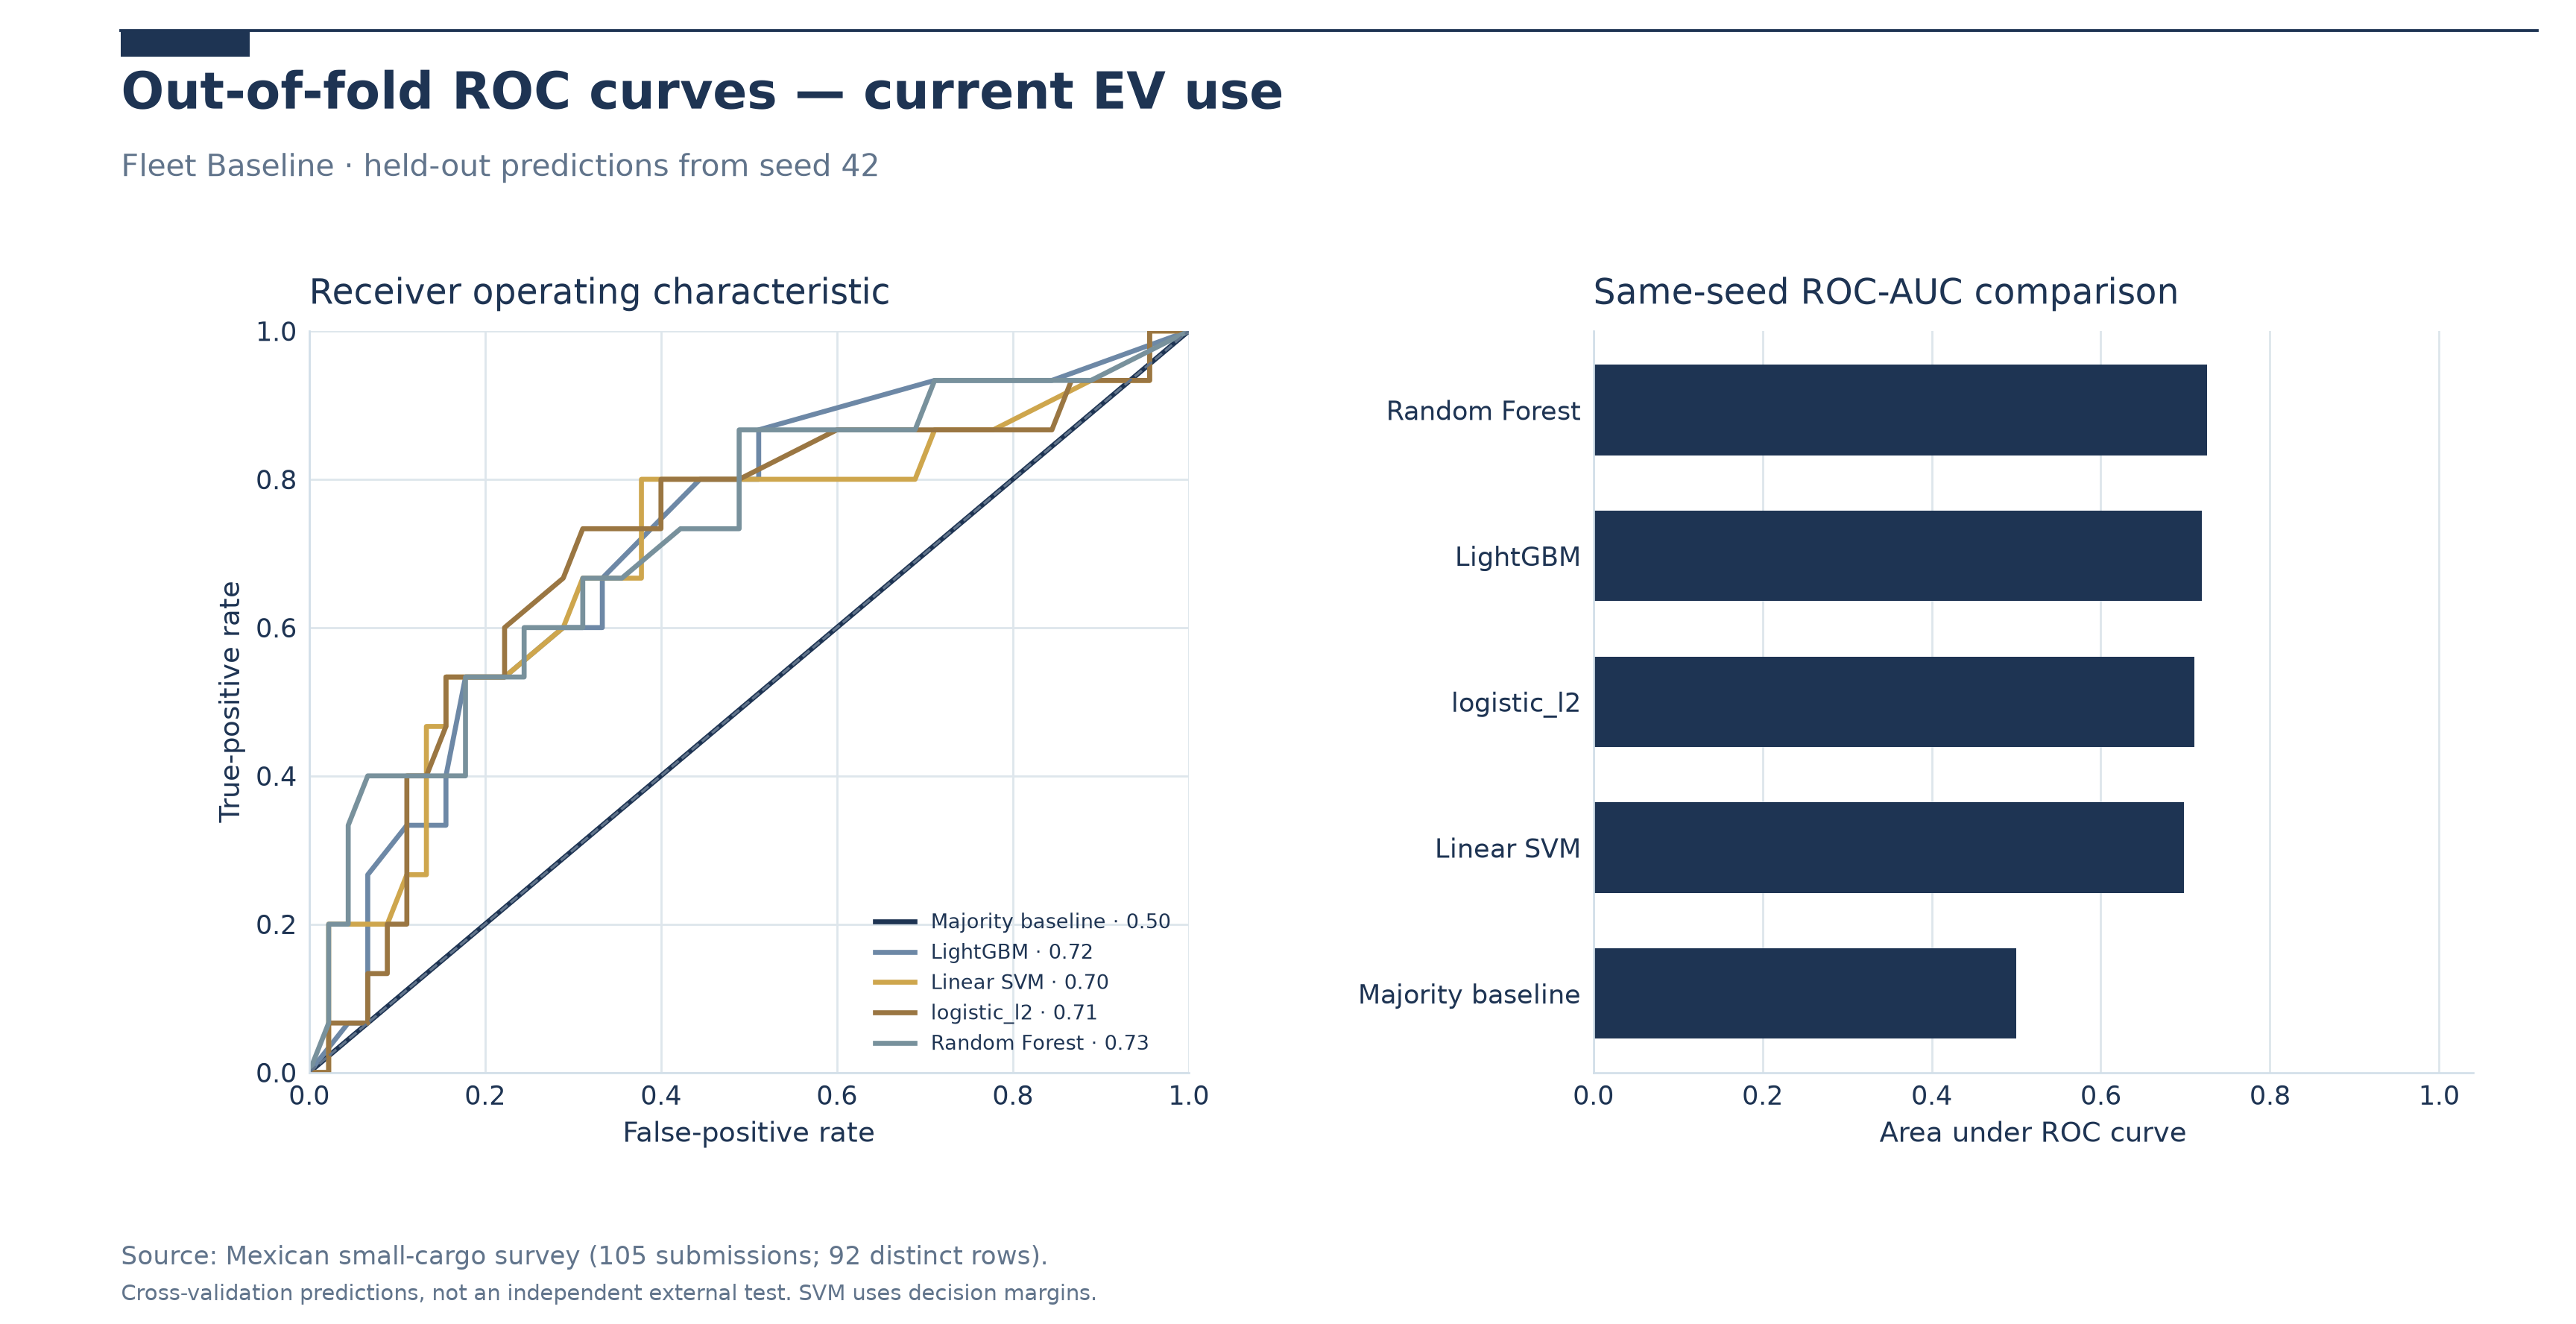

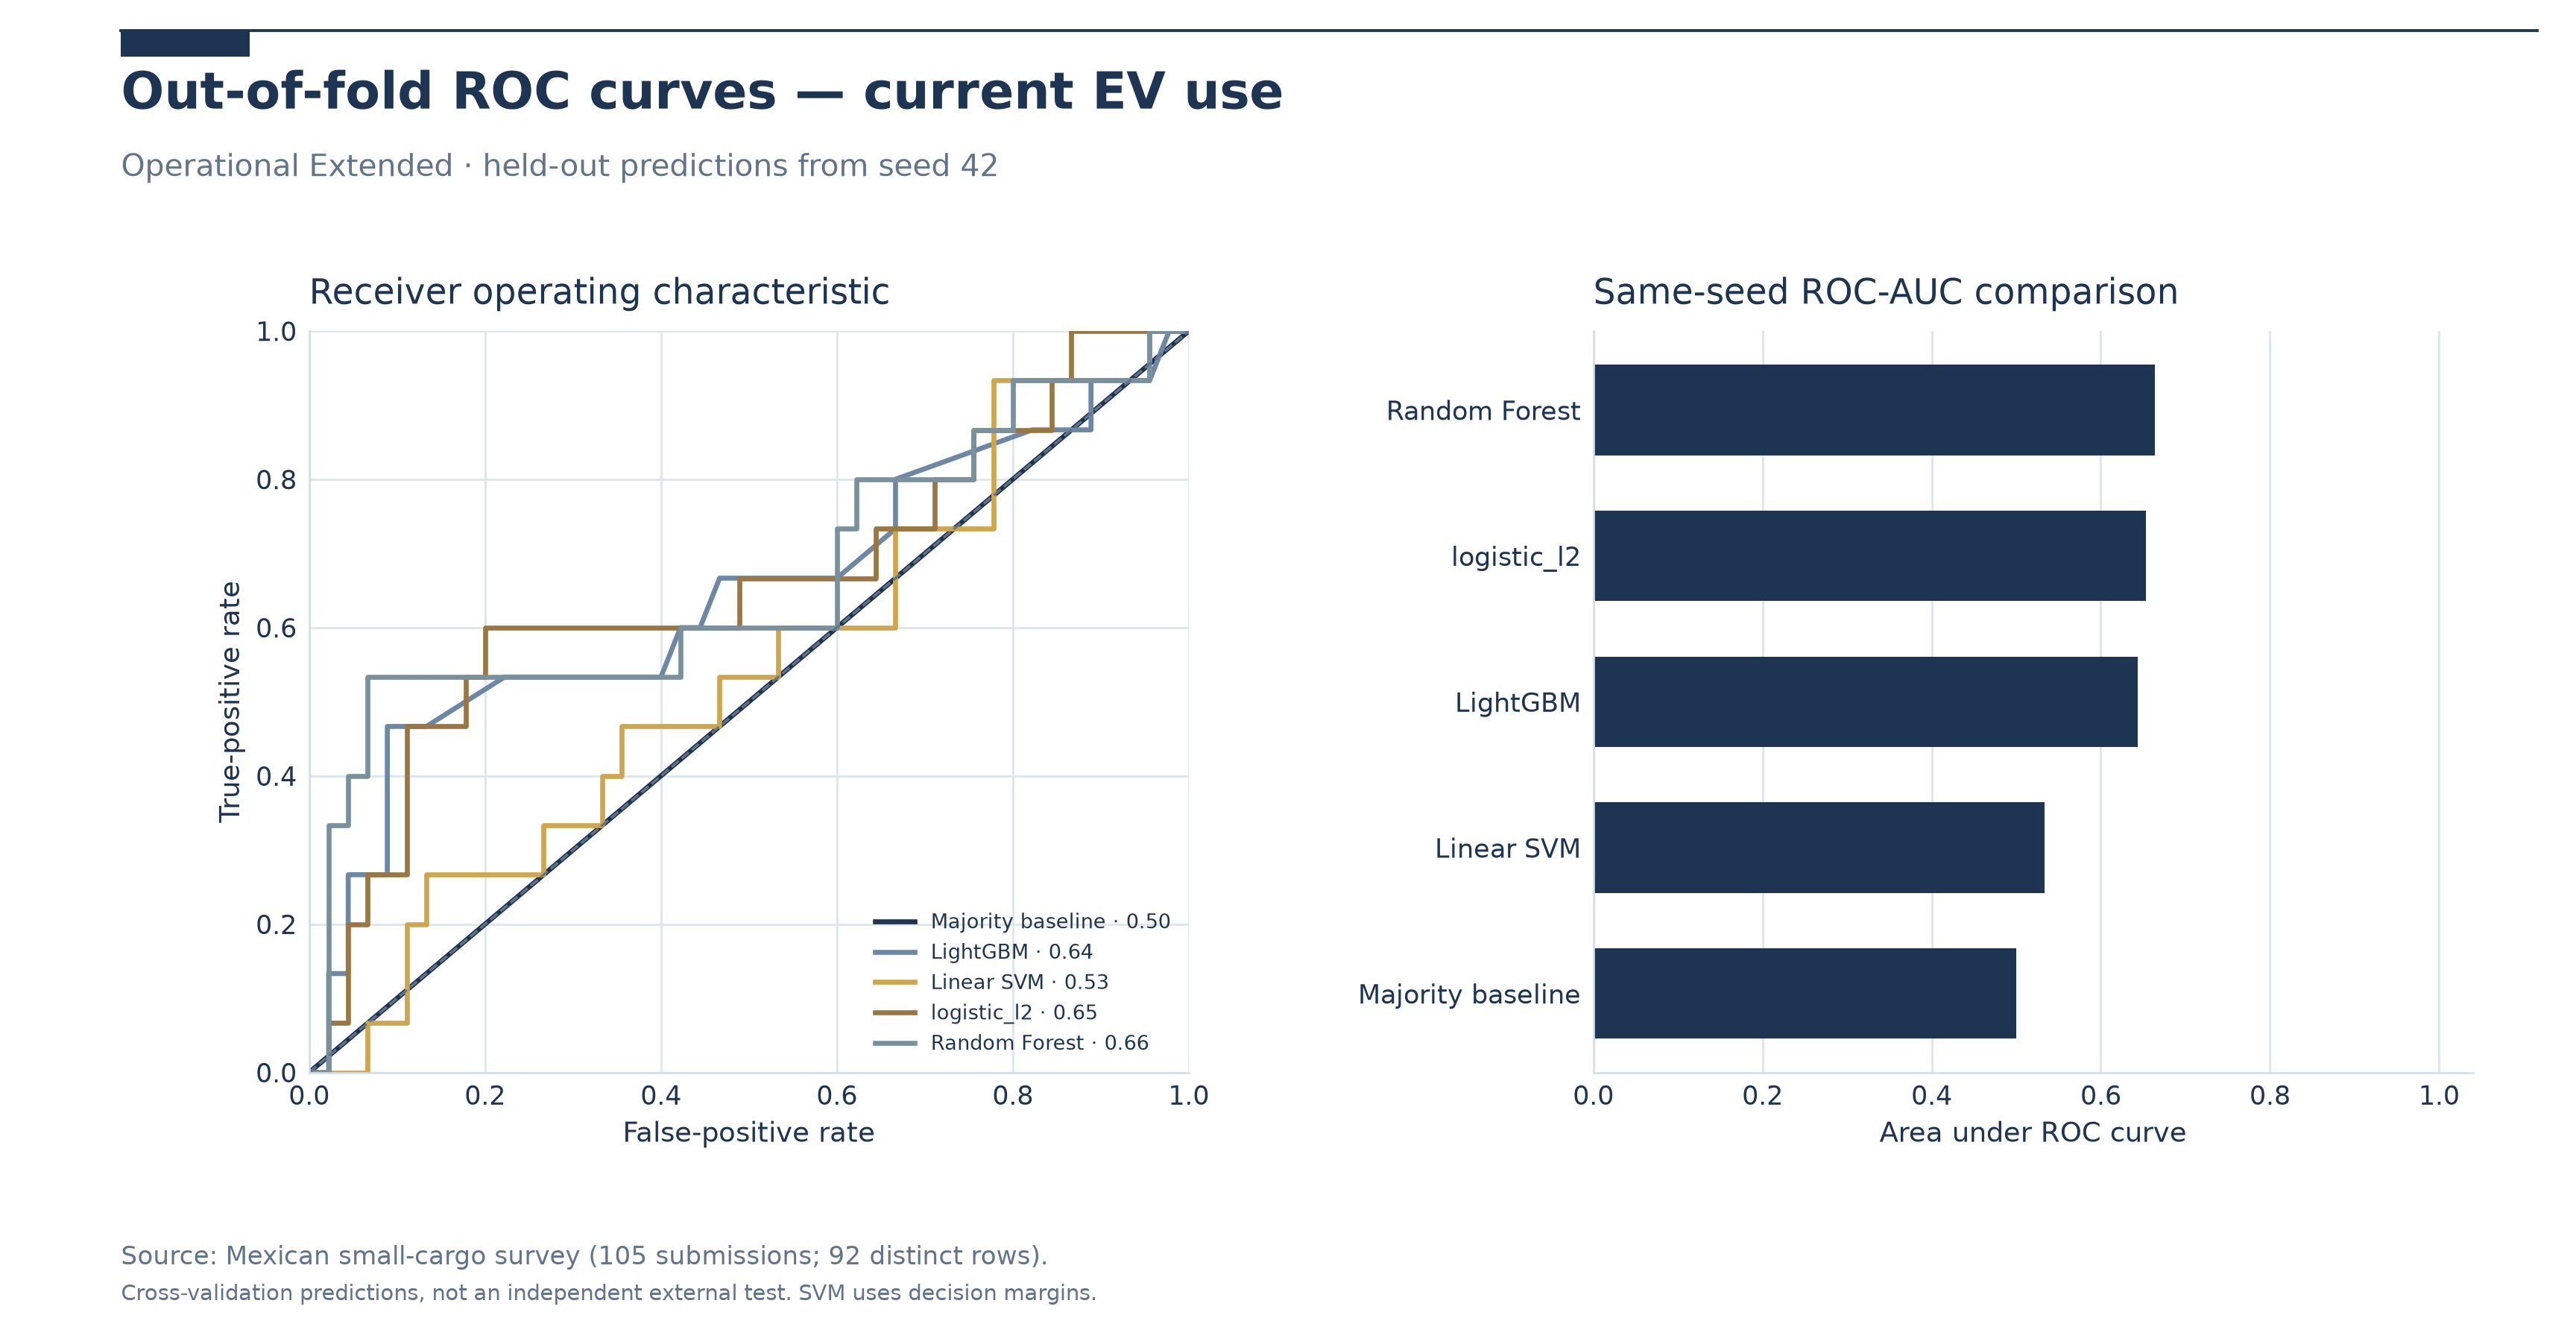

In [15]:
for scenario in FEATURE_SETS:
    plot_roc_dashboard(predictions,TARGET,scenario,seed=42)
    show_figure(FIGURES/('03_ev_use' if TARGET=='ev_use' else '04_ev_consideration')/f'03_roc_{scenario}.png')


## Precision–recall, confusion matrix, and split sensitivity

The highlighted model is the leading model by the saved multi-seed balanced-accuracy summary. Its confusion matrix is calculated using the same survey outcomes for selection and assessment; hence it is a **diagnostic**, not a fresh unbiased test. Precision–recall baseline prevalence is target-dependent.

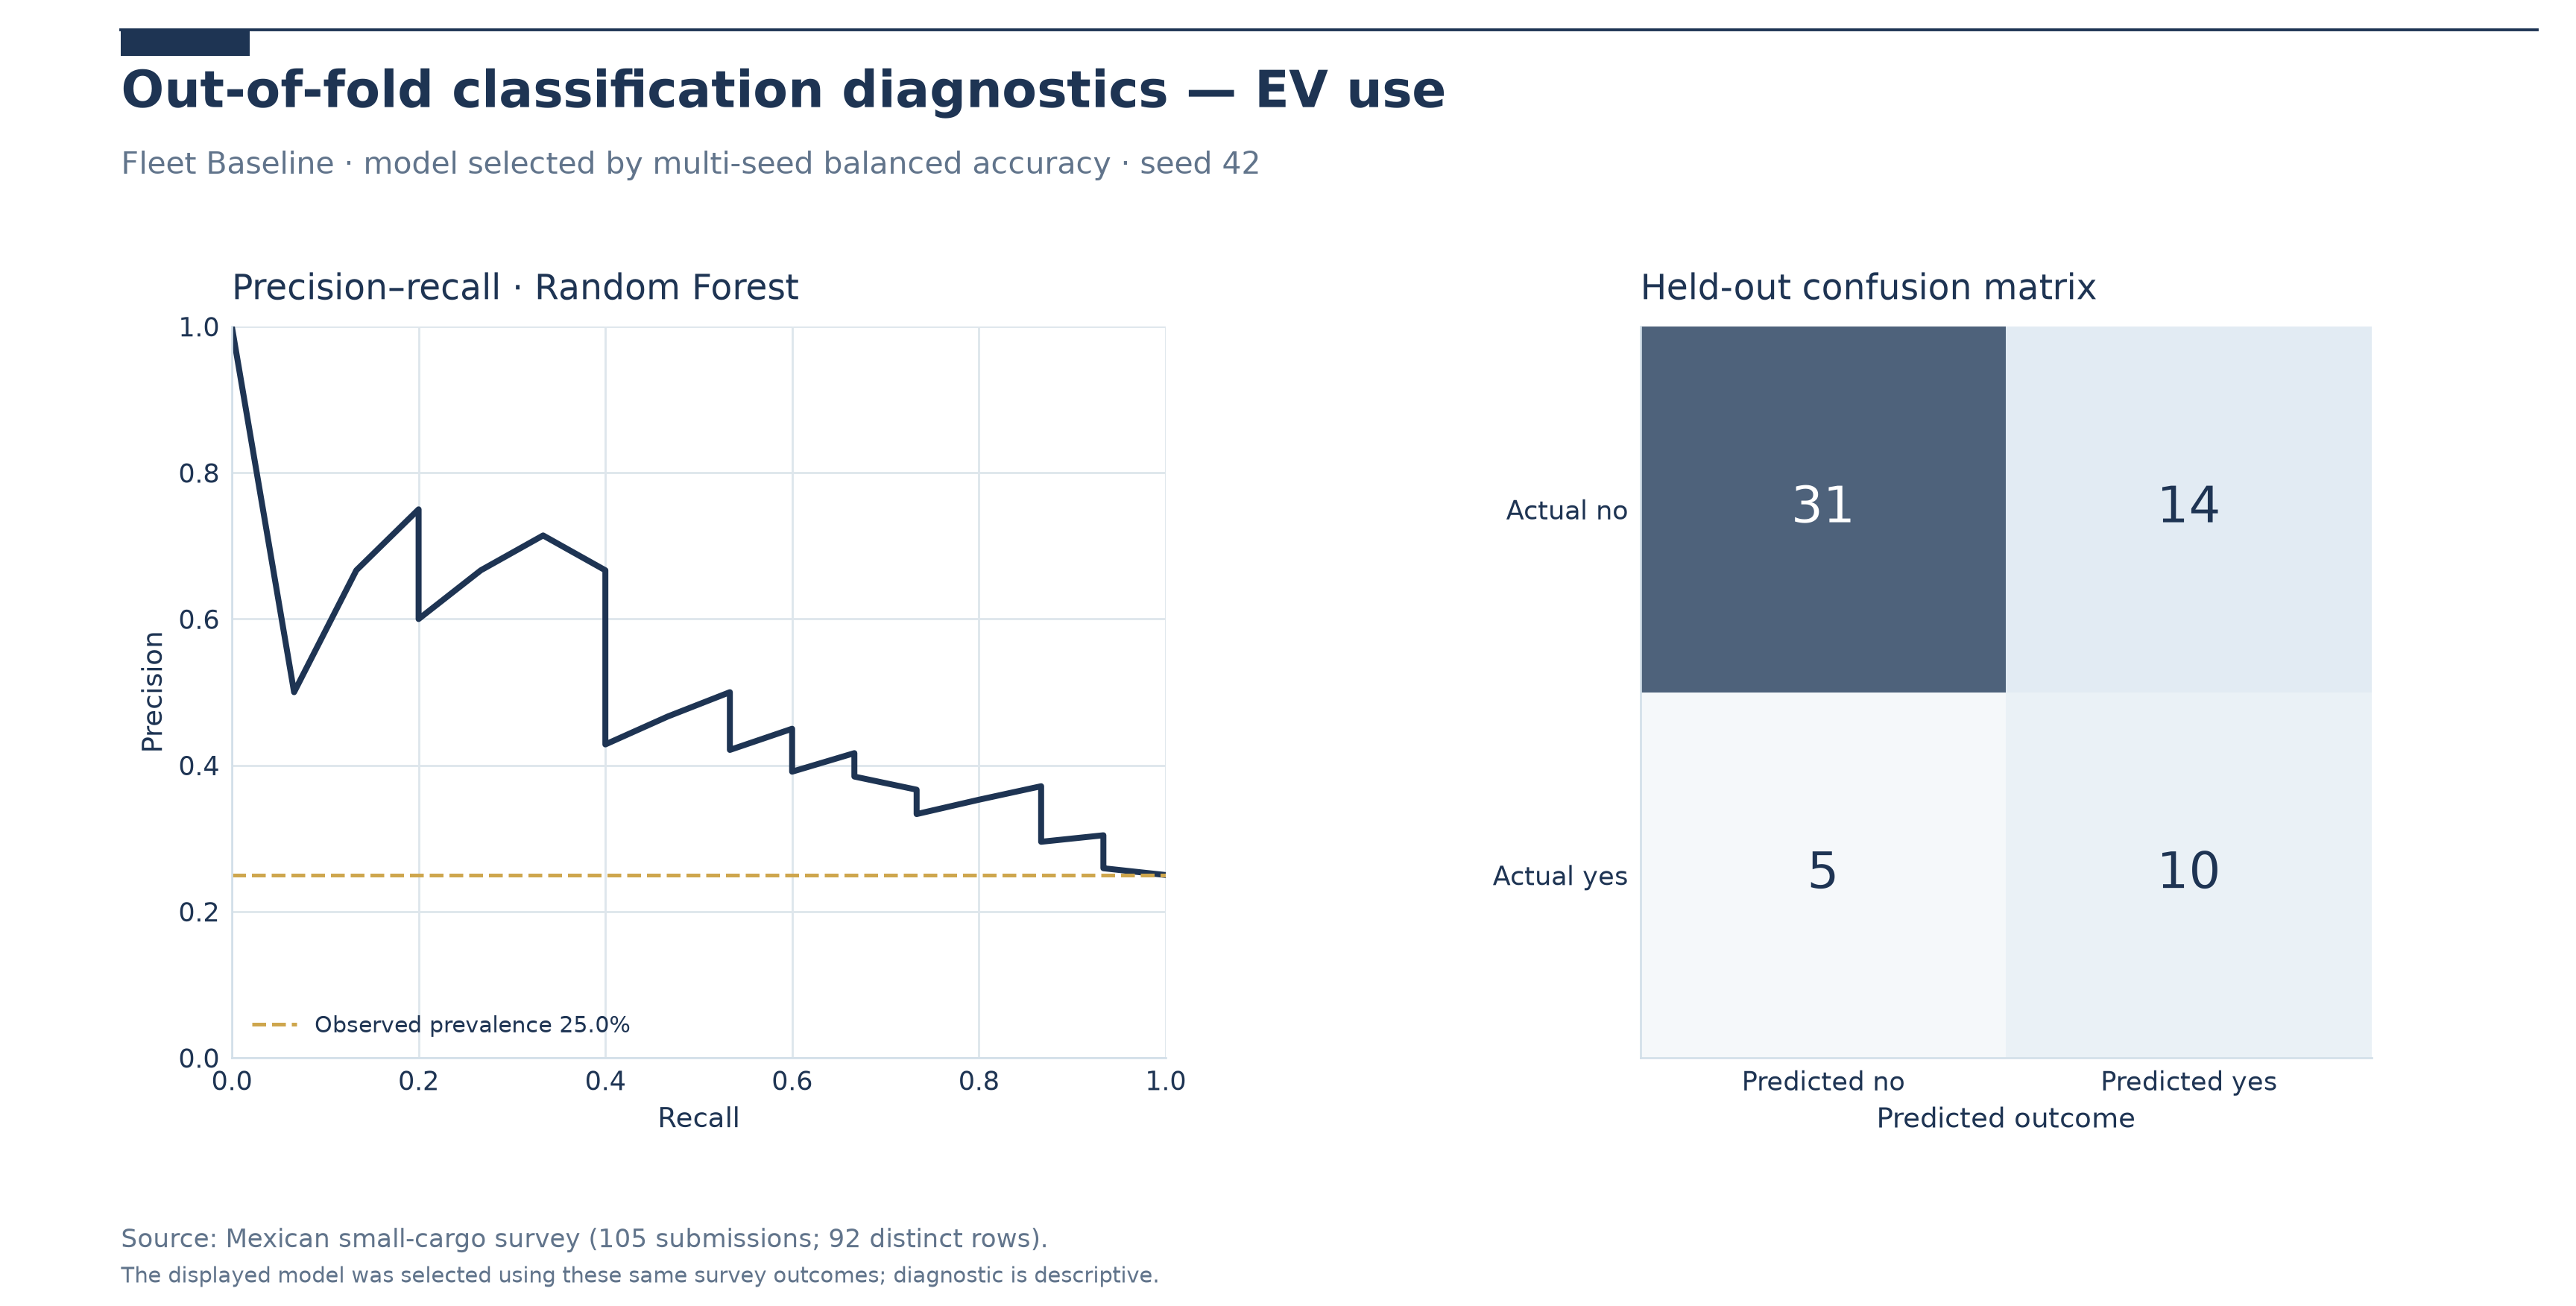

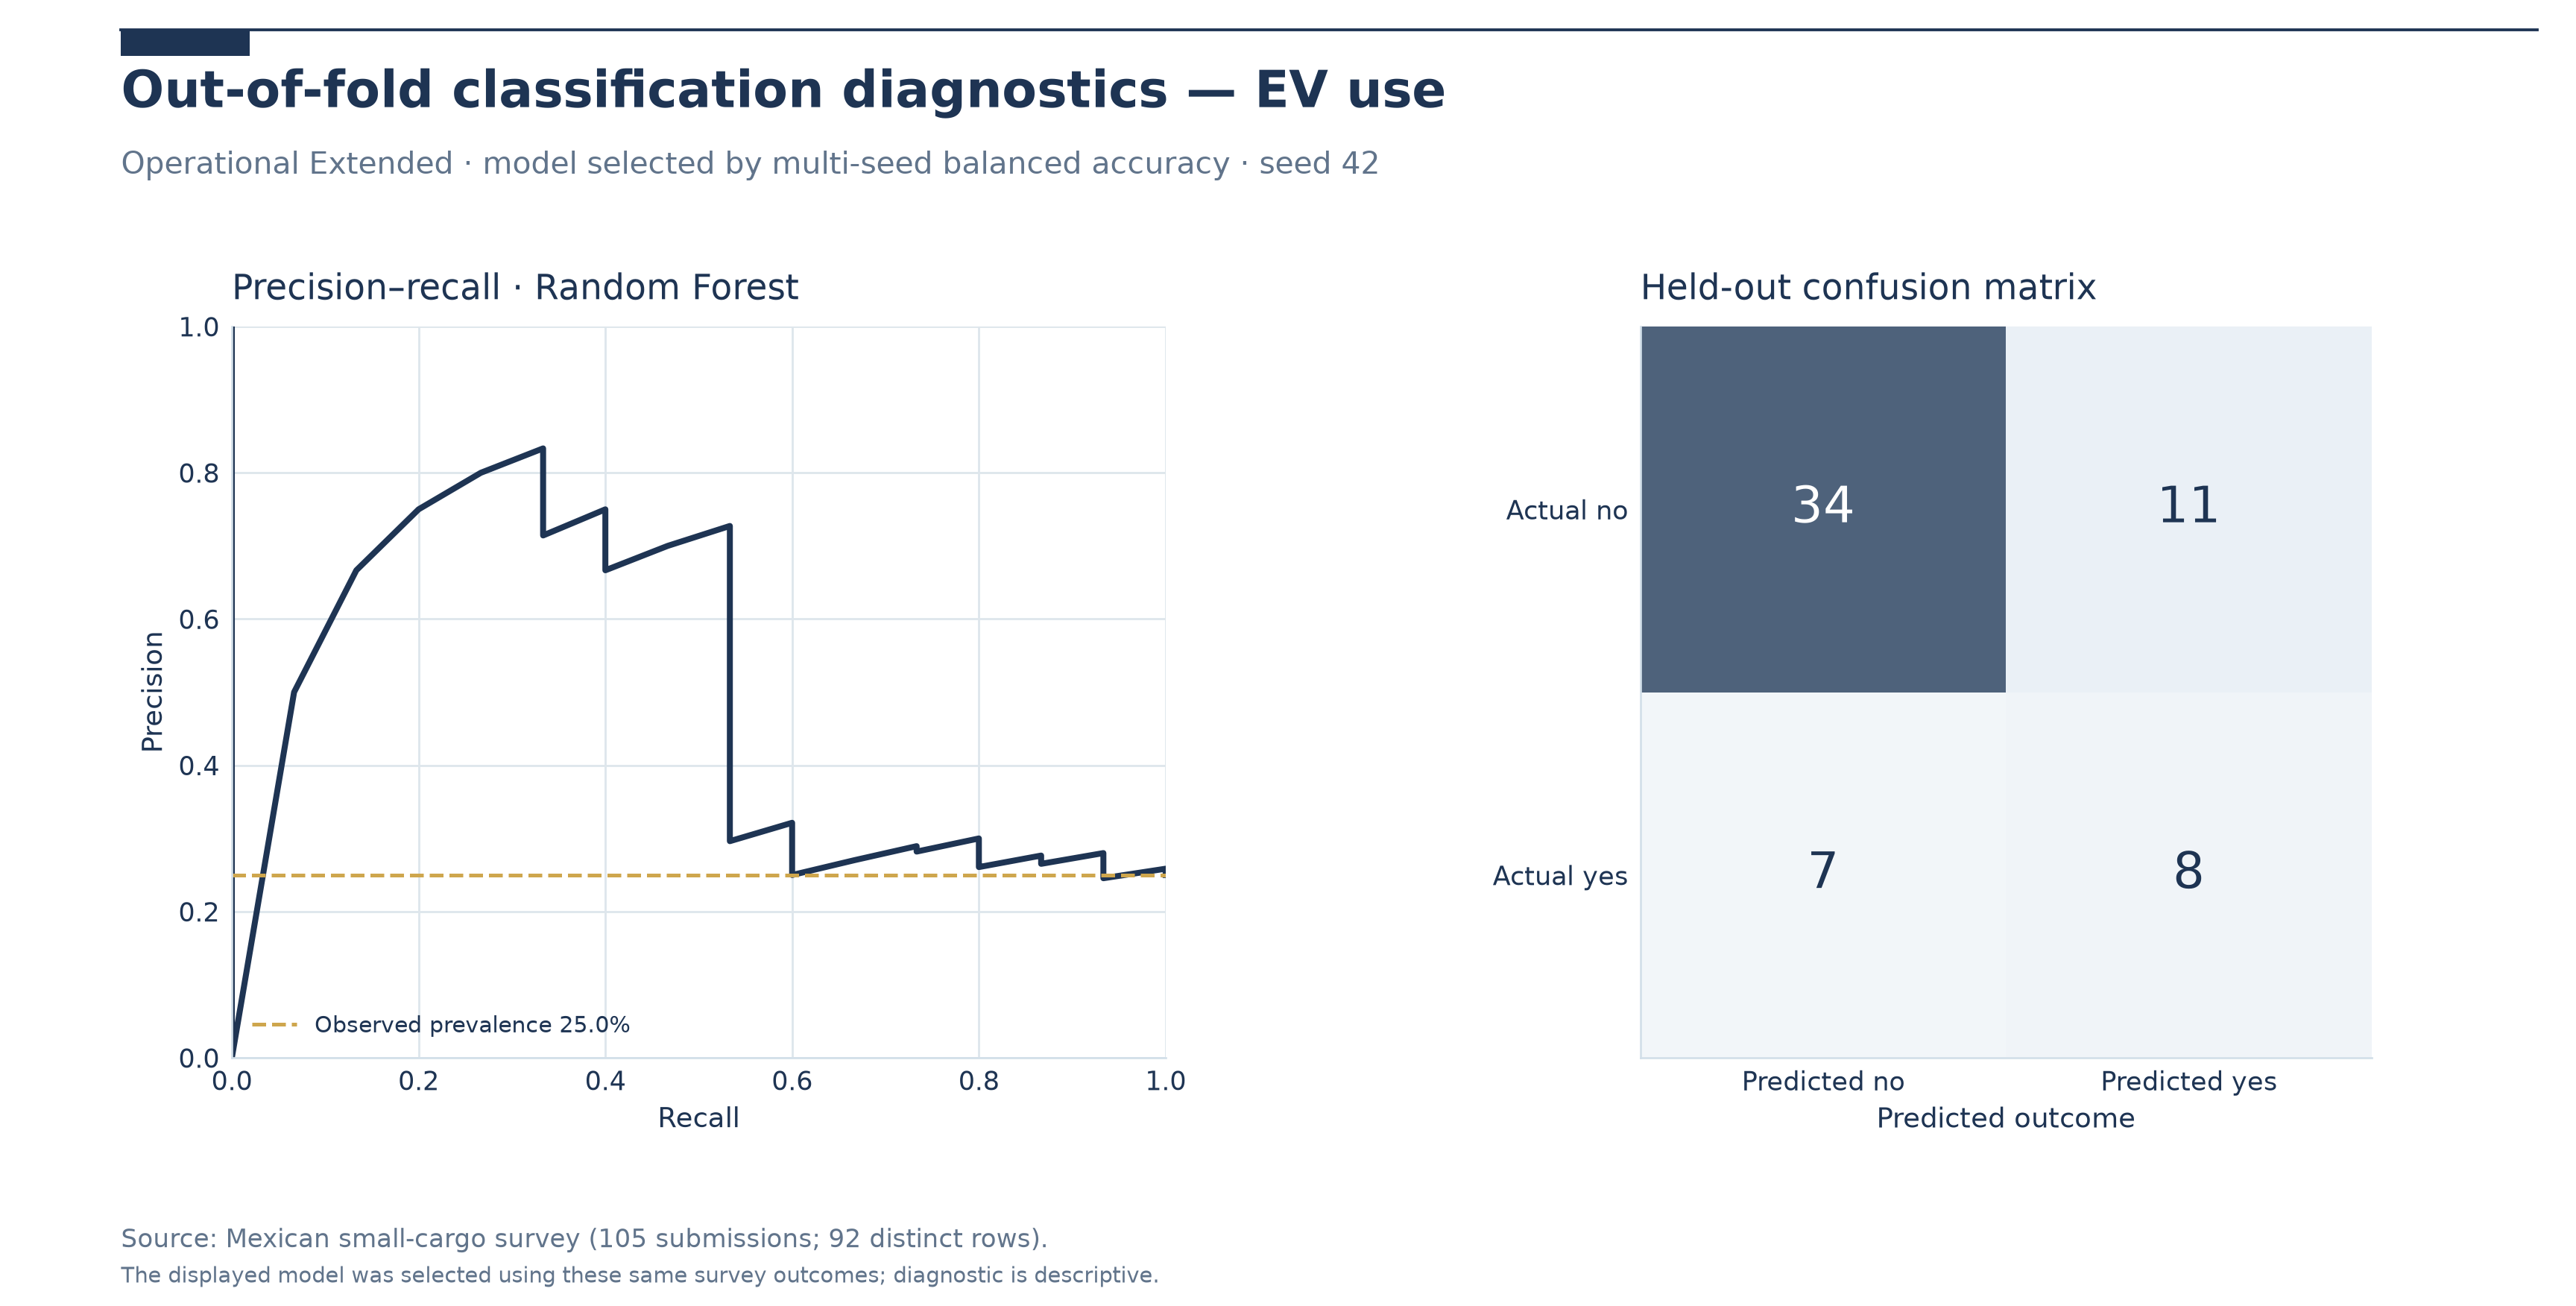

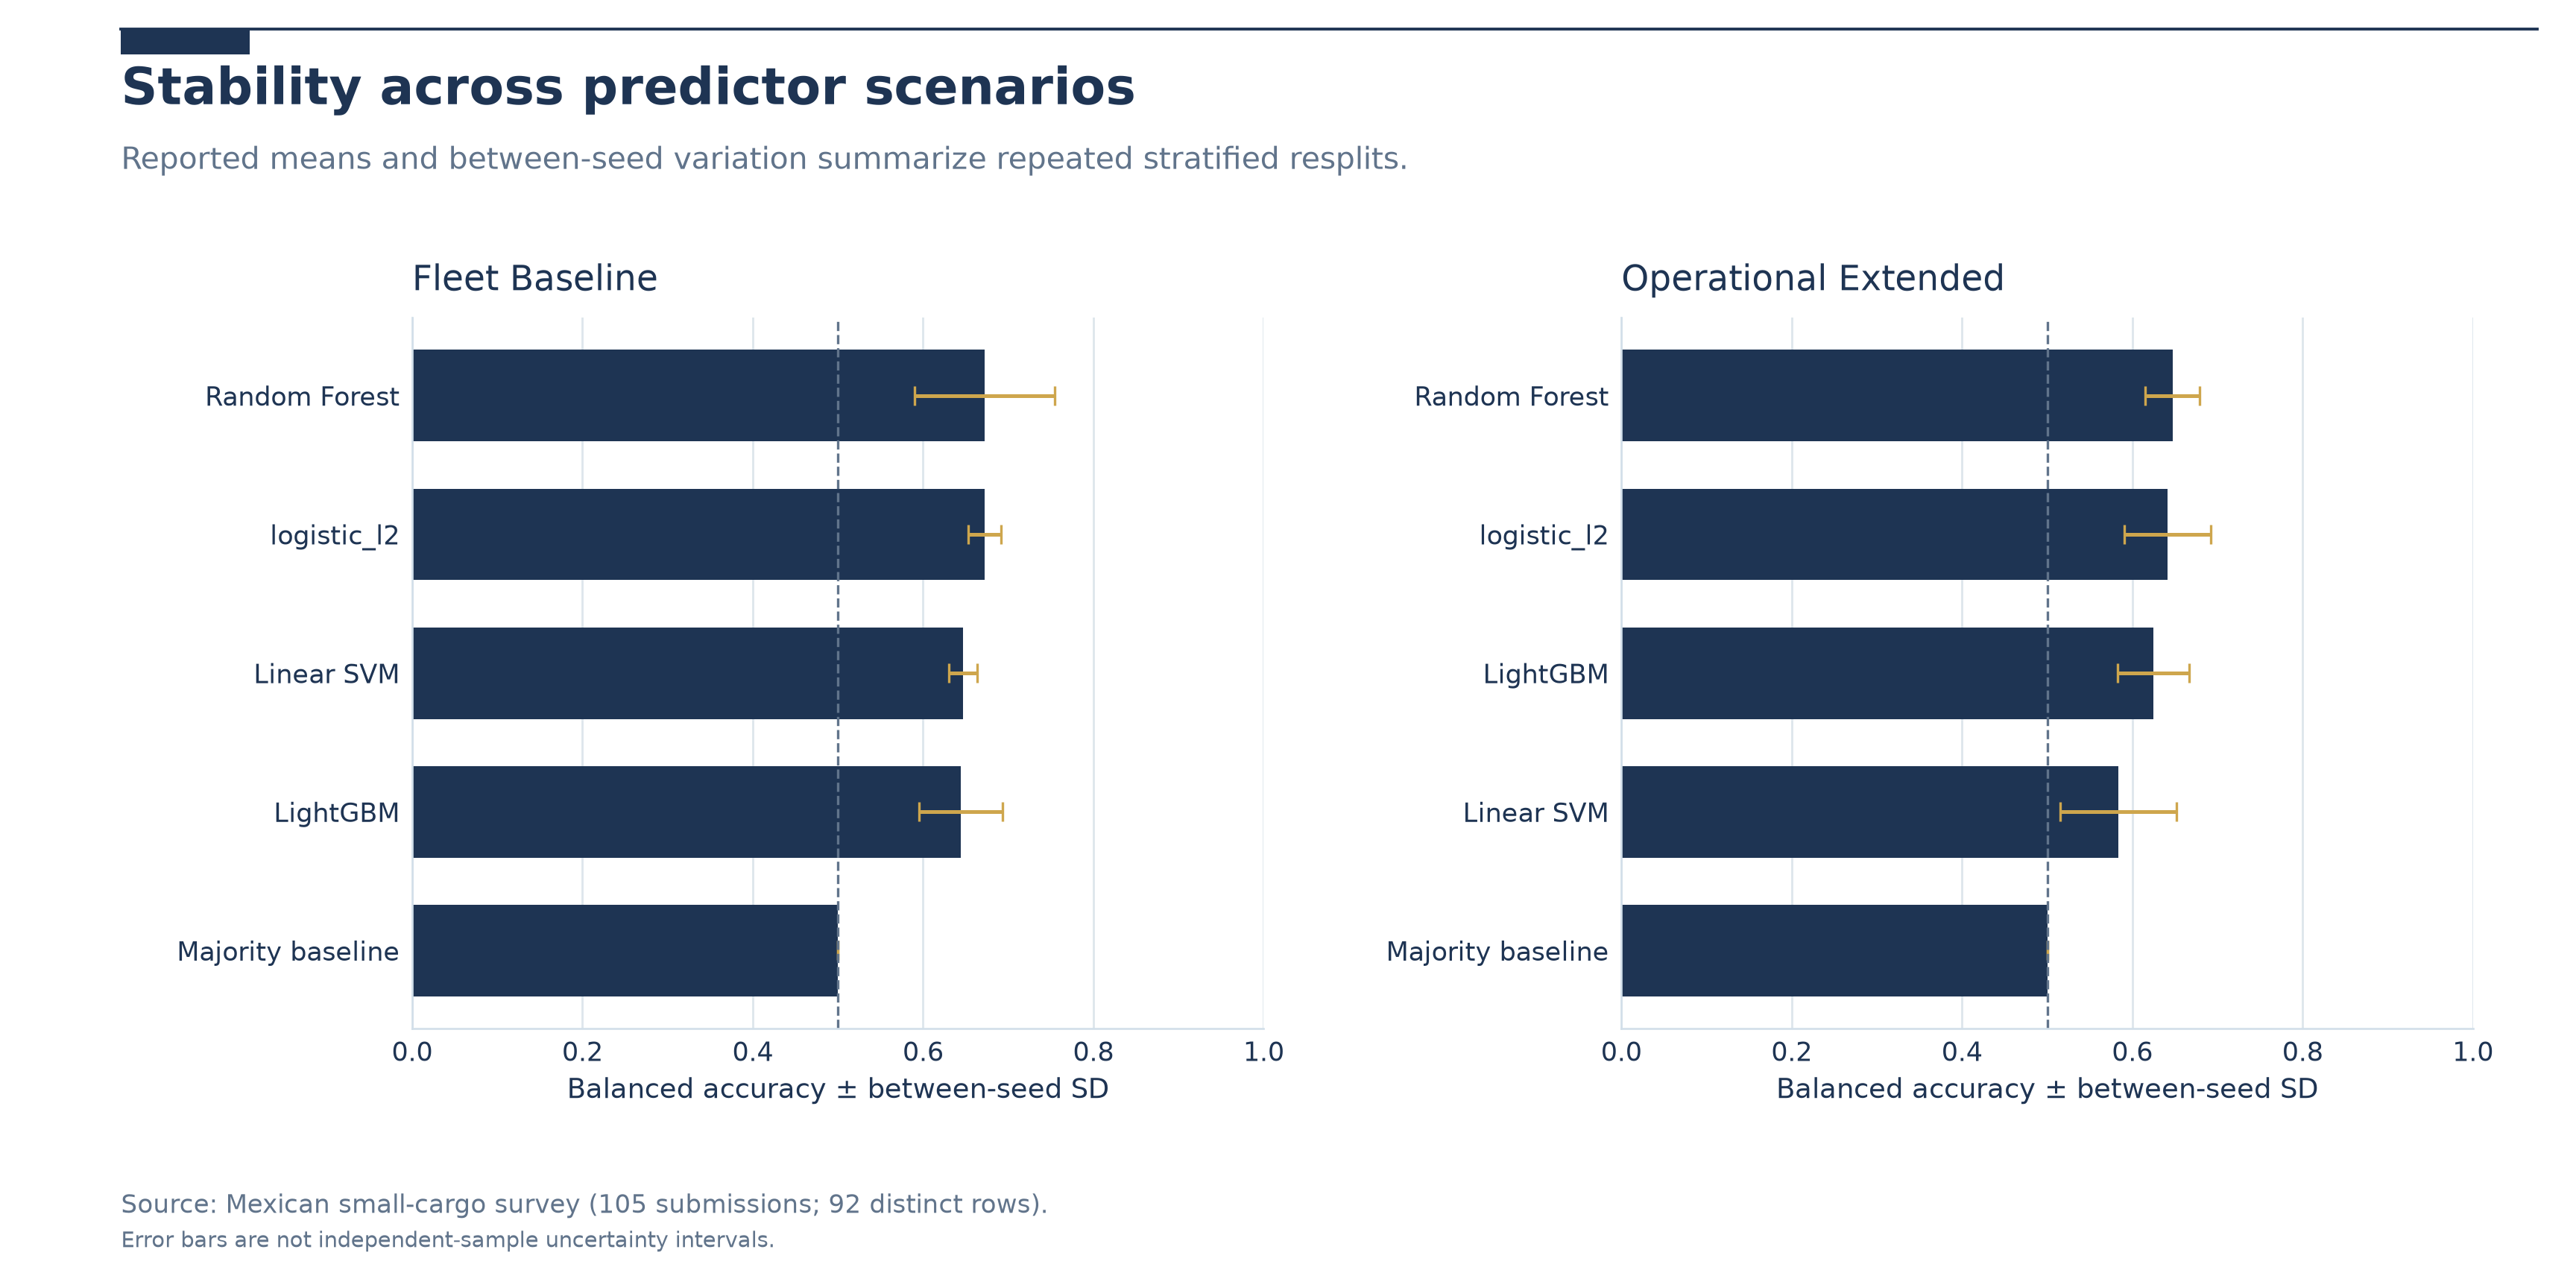

In [16]:
for scenario in FEATURE_SETS:
    plot_precision_recall_and_confusion(predictions,summary,TARGET,scenario,seed=42)
    show_figure(FIGURES/('03_ev_use' if TARGET=='ev_use' else '04_ev_consideration')/f'04_pr_confusion_{scenario}.png')
plot_seed_stability(summary,TARGET)
show_figure(FIGURES/('03_ev_use' if TARGET=='ev_use' else '04_ev_consideration')/'05_seed_stability.png')


## Interpretation and limitations

The data contain relatively few positive outcomes, selection bias is unresolved, and external geographic/operator validation is unavailable. The predictive metrics do not identify causally effective EV incentives. Confidence intervals or statistical significance for algorithm ranking should not be inferred from split-seed SD. A larger independent survey and a registered feature specification are needed before deployment or publication-strength claims.